Saving adult.csv to adult (11).csv
✅ Selected file: adult (11).csv
Target: income
Cleaned shape: (32537, 15)
Target counts:
 income
<=50k    24698
>50k      7839
Name: count, dtype: int64
Numeric cols: 6 | Categorical cols: 8

Running search...



,model,BEST_outliers,BEST_scaler,BEST_transform,BEST_dim_red,cv_acc,cv_f1,cv_roc_auc,test_acc,test_f1,test_prec,test_rec,test_roc_auc,test_log_loss
2,HistGB,out:none,standard,None,none,0.872066,0.713500,0.926056,0.868009,0.701217,0.771232,0.642857,0.920624,0.290953
0,LogReg,out:none,standard,None,svd,0.851128,0.659379,0.906341,0.850184,0.655842,0.734387,0.592474,0.900386,0.326652
3,RandomForest,out:none,standard,None,none,0.856622,0.679088,0.906831,0.849570,0.662530,0.720930,0.612883,0.894565,0.362772
1,LinearSVC,out:none,robust,None,svd,0.850590,0.651840,0.905522,0.848341,0.645347,0.739095,0.572704,0.897829,NaN



✅ BEST OVERALL MODEL: HistGB
Best pipeline: {'BEST_outliers': 'out:none', 'BEST_scaler': 'standard', 'BEST_transform': None, 'BEST_dim_red': 'none'}

Classification Report (Best Model):

              precision    recall  f1-score   support

           0     0.8923    0.9395    0.9153      4940
           1     0.7712    0.6429    0.7012      1568

    accuracy                         0.8680      6508
   macro avg     0.8318    0.7912    0.8083      6508
weighted avg     0.8632    0.8680    0.8637      6508



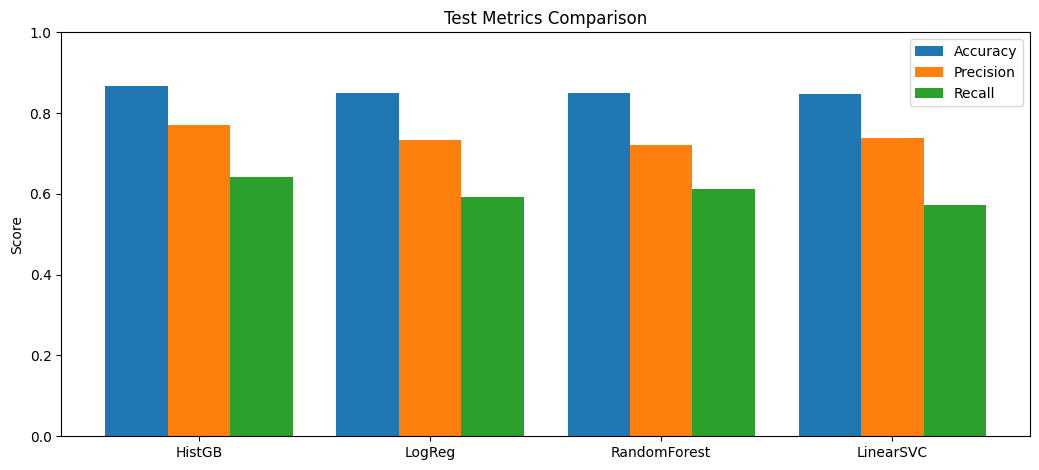

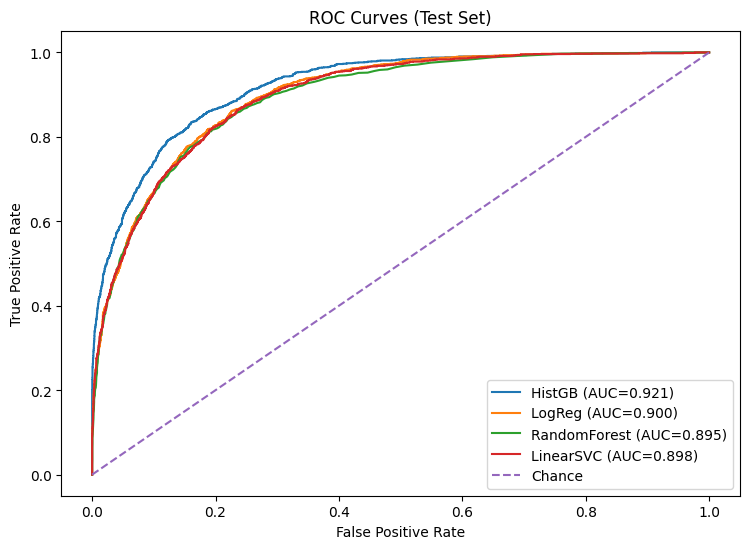

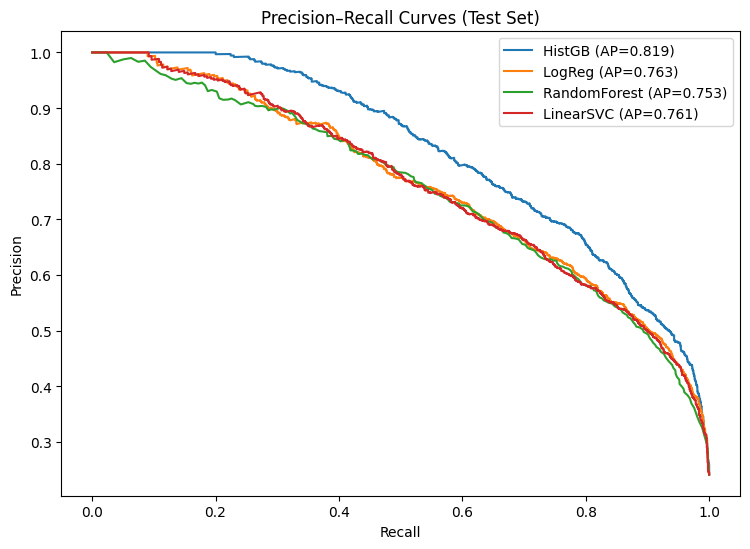

In [ ]:
!pip -q install scikit-learn pandas numpy

import os, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
    log_loss, roc_curve, auc, precision_recall_curve, average_precision_score, classification_report
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler, PowerTransformer
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.base import BaseEstimator, TransformerMixin

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
FOLDS = 3
N_JOBS_CV = -1

uploaded = files.upload()
DATA_PATH = next(iter(uploaded.keys()))
print("✅ Selected file:", DATA_PATH)

def load_csv_or_zip(path):
    if path.lower().endswith(".zip"):
        extract_dir = "/content/_extract"
        os.makedirs(extract_dir, exist_ok=True)
        with zipfile.ZipFile(path, "r") as z:
            z.extractall(extract_dir)
        csvs = [f for f in os.listdir(extract_dir) if f.lower().endswith(".csv")]
        if not csvs:
            raise FileNotFoundError("No CSV file found inside ZIP.")
        return pd.read_csv(os.path.join(extract_dir, csvs[0]))
    return pd.read_csv(path)

def force_numpy_nan(df_):
    out = df_.copy()
    out = out.replace({pd.NA: np.nan})
    out = out.where(pd.notna(out), np.nan)
    return out

df = load_csv_or_zip(DATA_PATH)
df = force_numpy_nan(df)
df.columns = [c.strip().replace(" ", "_") for c in df.columns]
df = df.replace("?", np.nan)
df = force_numpy_nan(df)

obj_cols = df.select_dtypes(include=["object"]).columns.tolist()
for c in obj_cols:
    s = df[c].astype(str).str.strip()
    s = s.replace(["", "nan", "None", "NaN"], np.nan)
    df[c] = s
df = force_numpy_nan(df)

possible_targets = [c for c in df.columns if c.lower() in ["income","target","label","class","y"]]
target_col = possible_targets[0] if possible_targets else df.columns[-1]
print("Target:", target_col)

nunique = df.nunique(dropna=False)
single_value_cols = nunique[nunique <= 1].index.tolist()
if single_value_cols:
    df.drop(columns=single_value_cols, inplace=True)

dup_count = int(df.duplicated().sum())
if dup_count > 0:
    df = df.drop_duplicates()

df = force_numpy_nan(df)
print("Cleaned shape:", df.shape)

y_raw = df[target_col].astype(str).str.strip().str.replace(r"\.$", "", regex=True).str.lower()
y_raw = y_raw.replace(["nan","none"], np.nan)
mask = pd.notna(y_raw)
df = df.loc[mask].copy()
y_raw = y_raw.loc[mask].copy()

X = df.drop(columns=[target_col]).copy()
X = force_numpy_nan(X)

for c in X.columns:
    if X[c].dtype == "object":
        conv = pd.to_numeric(X[c], errors="coerce")
        orig_nonnull = X[c].notna().sum()
        conv_nonnull = conv.notna().sum()
        if orig_nonnull > 0 and (conv_nonnull / orig_nonnull) >= 0.9:
            X[c] = conv

X = force_numpy_nan(X)

counts = y_raw.value_counts(dropna=True)
print("Target counts:\n", counts)

if len(counts) == 2:
    classes = sorted(counts.index.tolist())
    y = y_raw.map({classes[0]: 0, classes[1]: 1}).astype("int64").to_numpy()
else:
    y = pd.Categorical(y_raw).codes.astype("int64")

num_cols = X.select_dtypes(include=["number"]).columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
print(f"Numeric cols: {len(num_cols)} | Categorical cols: {len(cat_cols)}")

min_class = int(pd.Series(y).value_counts().min())
if min_class >= 2:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
    )
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE, shuffle=True
    )

X_train = force_numpy_nan(X_train)
X_test = force_numpy_nan(X_test)

def iqr_clip(Xtr, Xte, numeric_cols, k=1.5):
    Xtr = Xtr.copy(); Xte = Xte.copy()
    for c in numeric_cols:
        s = Xtr[c]
        if s.notna().sum() < 10:
            continue
        q1 = s.quantile(0.25); q3 = s.quantile(0.75)
        iqr = q3 - q1
        if pd.isna(iqr) or iqr == 0:
            continue
        lo, hi = q1 - k*iqr, q3 + k*iqr
        Xtr[c] = Xtr[c].clip(lo, hi)
        Xte[c] = Xte[c].clip(lo, hi)
    return Xtr, Xte

outlier_variants = [("out:none", X_train.copy(), y_train.copy(), X_test.copy(), y_test.copy())]
if len(num_cols) > 0:
    Xtr_iqr, Xte_iqr = iqr_clip(X_train, X_test, num_cols)
    outlier_variants.append(("out:iqr", Xtr_iqr, y_train.copy(), Xte_iqr, y_test.copy()))

def make_preprocessor(scaler="standard", transform=None):
    sc = StandardScaler() if scaler == "standard" else RobustScaler()
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if transform == "yeo":
        num_steps.append(("power", PowerTransformer(method="yeo-johnson", standardize=False)))
    num_steps += [("scaler", sc), ("var", VarianceThreshold(1e-6))]
    num_pipe = Pipeline(steps=num_steps)
    cat_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
    ])
    return ColumnTransformer(
        [("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)],
        remainder="drop",
        sparse_threshold=0.3
    )

class SafeTruncatedSVD(BaseEstimator, TransformerMixin):
    def __init__(self, requested_components=120, random_state=42):
        self.requested_components = requested_components
        self.random_state = random_state
        self.svd_ = None
    def fit(self, X, y=None):
        n_features = X.shape[1]
        if n_features < 2:
            self.svd_ = None
            return self
        n_comp = min(self.requested_components, n_features - 1)
        self.svd_ = TruncatedSVD(n_components=n_comp, random_state=self.random_state)
        self.svd_.fit(X)
        return self
    def transform(self, X):
        if self.svd_ is None:
            return X
        return self.svd_.transform(X)

class ToDense(BaseEstimator, TransformerMixin):
    def __init__(self, dtype=np.float32):
        self.dtype = dtype
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        try:
            import scipy.sparse as sp
            if sp.issparse(X):
                return X.toarray().astype(self.dtype, copy=False)
        except Exception:
            pass
        return np.asarray(X, dtype=self.dtype)

models = {
    "LogReg": LogisticRegression(max_iter=3000, n_jobs=-1),
    "LinearSVC": LinearSVC(),
    "HistGB": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(n_estimators=250, random_state=RANDOM_STATE, n_jobs=-1),
}
DENSE_ONLY = {"HistGB", "RandomForest"}
SCORING = {"acc":"accuracy", "f1":"f1", "prec":"precision", "rec":"recall", "roc_auc":"roc_auc"}

def build_pipe(model_name, pre, dim_red, model):
    steps = [("pre", pre)]
    if dim_red == "svd":
        steps.append(("svd", SafeTruncatedSVD(requested_components=120, random_state=RANDOM_STATE)))
    if model_name in DENSE_ONLY:
        steps.append(("todense", ToDense(dtype=np.float32)))
    steps.append(("model", model))
    return Pipeline(steps=steps)

def cv_eval(pipe, Xtr, ytr):
    cv = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=RANDOM_STATE)
    res = cross_validate(pipe, Xtr, ytr, cv=cv, scoring=SCORING, n_jobs=N_JOBS_CV, error_score="raise")
    return {m: float(np.mean(res["test_"+m])) for m in SCORING.keys()}

scalers = ["standard", "robust"]
transforms = [None, "yeo"]
dimreds = ["none", "svd"]

rows = []
best_for_model = {}

print("\nRunning search...\n")
for model_name, model in models.items():
    best_obj = None
    best_pack = None
    for out_tag, Xtr0, ytr0, Xte0, yte0 in outlier_variants:
        Xtr0 = force_numpy_nan(Xtr0)
        Xte0 = force_numpy_nan(Xte0)
        for sc in scalers:
            for tfm in transforms:
                pre = make_preprocessor(scaler=sc, transform=tfm)
                for dr in dimreds:
                    pipe = build_pipe(model_name, pre, dr, model)
                    scores = cv_eval(pipe, Xtr0, ytr0)
                    row = {
                        "model": model_name,
                        "outliers": out_tag,
                        "scaler": sc,
                        "transform": tfm,
                        "dim_red": dr,
                        "cv_acc": scores["acc"],
                        "cv_f1": scores["f1"],
                        "cv_roc_auc": scores["roc_auc"],
                        "cv_prec": scores["prec"],
                        "cv_rec": scores["rec"],
                    }
                    rows.append(row)
                    obj = (scores["acc"], scores["f1"], scores["roc_auc"])
                    if best_obj is None or obj > best_obj:
                        best_obj = obj
                        best_pack = (pipe, row, (Xtr0, ytr0, Xte0, yte0))
    best_for_model[model_name] = best_pack

results_df = pd.DataFrame(rows)

final_rows = []
test_scores_store = {}

for model_name, (pipe, best_row, pack) in best_for_model.items():
    Xtr, ytr, Xte, yte = pack
    pipe.fit(Xtr, ytr)
    pred = pipe.predict(Xte)

    roc = np.nan
    score_vec = None
    proba_vec = None

    if hasattr(pipe, "predict_proba"):
        try:
            proba_vec = pipe.predict_proba(Xte)[:, 1]
            score_vec = proba_vec
            roc = roc_auc_score(yte, proba_vec)
        except Exception:
            proba_vec = None

    if (score_vec is None) and hasattr(pipe, "decision_function"):
        try:
            score_vec = pipe.decision_function(Xte)
            roc = roc_auc_score(yte, score_vec)
        except Exception:
            score_vec = None

    ll = np.nan
    if proba_vec is not None:
        ll = log_loss(yte, np.column_stack([1 - proba_vec, proba_vec]))

    test_scores_store[model_name] = {"y_true": yte, "y_score": score_vec, "y_proba": proba_vec}

    final_rows.append({
        "model": model_name,
        "BEST_outliers": best_row["outliers"],
        "BEST_scaler": best_row["scaler"],
        "BEST_transform": best_row["transform"],
        "BEST_dim_red": best_row["dim_red"],
        "cv_acc": best_row["cv_acc"],
        "cv_f1": best_row["cv_f1"],
        "cv_roc_auc": best_row["cv_roc_auc"],
        "test_acc": accuracy_score(yte, pred),
        "test_f1": f1_score(yte, pred),
        "test_prec": precision_score(yte, pred),
        "test_rec": recall_score(yte, pred),
        "test_roc_auc": roc,
        "test_log_loss": ll,
    })

final_df = pd.DataFrame(final_rows).sort_values("test_acc", ascending=False)
display(final_df)

best_model = final_df.iloc[0]["model"]
print("\n✅ BEST OVERALL MODEL:", best_model)
print("Best pipeline:", final_df.iloc[0][["BEST_outliers","BEST_scaler","BEST_transform","BEST_dim_red"]].to_dict())

pipe_best, best_row, pack_best = best_for_model[best_model]
Xtrb, ytrb, Xteb, yteb = pack_best
pipe_best.fit(Xtrb, ytrb)
pred_best = pipe_best.predict(Xteb)
print("\nClassification Report (Best Model):\n")
print(classification_report(yteb, pred_best, digits=4))

plot_df = final_df.sort_values("test_acc", ascending=False).reset_index(drop=True)
x = np.arange(len(plot_df["model"]))
w = 0.27

fig = plt.figure(figsize=(10.5, 4.8))
plt.bar(x - w, plot_df["test_acc"],  w, label="Accuracy")
plt.bar(x,     plot_df["test_prec"], w, label="Precision")
plt.bar(x + w, plot_df["test_rec"],  w, label="Recall")
plt.xticks(x, plot_df["model"])
plt.ylim(0, 1)
plt.title("Test Metrics Comparison")
plt.ylabel("Score")
plt.legend()
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(7.6, 5.6))
any_roc = False
for model_name in plot_df["model"].tolist():
    y_true = test_scores_store[model_name]["y_true"]
    y_score = test_scores_store[model_name]["y_score"]
    if y_score is None:
        continue
    fpr, tpr, _ = roc_curve(y_true, y_score)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{model_name} (AUC={roc_auc:.3f})")
    any_roc = True
plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
plt.title("ROC Curves (Test Set)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(7.6, 5.6))
any_pr = False
for model_name in plot_df["model"].tolist():
    y_true = test_scores_store[model_name]["y_true"]
    y_score = test_scores_store[model_name]["y_score"]
    if y_score is None:
        continue
    prec, rec, _ = precision_recall_curve(y_true, y_score)
    ap = average_precision_score(y_true, y_score)
    plt.plot(rec, prec, label=f"{model_name} (AP={ap:.3f})")
    any_pr = True
plt.title("Precision–Recall Curves (Test Set)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.tight_layout()
plt.show()



